## Лабораторная работа №1 | Вариант 5

Выполнил: М8О-310БВ-24 Самойлов Дмитрий Алексеевич

### 1. Numpy

In [1]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [3]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [4]:
custom_dtype = np.dtype([
    ('red', np.uint8),
    ('green', np.uint8),
    ('blue', np.uint8),
    ('alpha', np.uint8)
])

3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [12]:
np.seterr(all='ignore')

{'divide': 'warn', 'over': 'warn', 'under': 'warn', 'invalid': 'warn'}

4. Создайте случайный вектор размера 10 и отсортируйте его

In [9]:
np.sort(np.random.random(10))

array([0.16901896, 0.18466177, 0.29753399, 0.34484828, 0.61038399,
       0.61507375, 0.88303642, 0.89044029, 0.91122671, 0.91712061])

5. Создайте read-only массив(неизменяемый)

In [29]:
arr = np.array([52, 67, 255, 0], dtype=np.uint8)

arr.flags.writeable = False

try:
    arr[0] = 100
except ValueError as e:
    print(f"Error: {e}")

Error: assignment destination is read-only


6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [25]:
cartesian_coords = np.random.random((10, 2))

x = cartesian_coords[:, 0]
y = cartesian_coords[:, 1]

r = np.hypot(x, y)

phi = np.arctan2(y, x)

polar_coords = np.column_stack((r, phi))

print('Cartesian coordinates (x, y) format:')
print(cartesian_coords)
print('Polar coordinates (r, phi) format:')
print(polar_coords)

Cartesian coordinates (x, y) format:
[[0.74188939 0.54025891]
 [0.21376294 0.03936484]
 [0.38272716 0.85916632]
 [0.31740389 0.56395777]
 [0.62890949 0.29999382]
 [0.49497338 0.73703066]
 [0.32620908 0.28388046]
 [0.33888738 0.11734112]
 [0.09592026 0.14910335]
 [0.08229429 0.20671344]]
Polar coordinates (r, phi) format:
[[0.91775789 0.62941577]
 [0.21735727 0.18211154]
 [0.94055667 1.15172143]
 [0.64714264 1.05816762]
 [0.69679512 0.44508406]
 [0.88781352 0.97940146]
 [0.43243552 0.71612816]
 [0.35862737 0.33333377]
 [0.17729215 0.99913572]
 [0.22249224 1.191922  ]]


7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [45]:
n_x, n_y = 5, 6

x = np.linspace(0, 1, n_x)
y = np.linspace(0, 1, n_y)

X, Y = np.meshgrid(x, y)

custom_dtype = np.dtype([
    ('x', np.float64),
    ('y', np.float64),
])

grid = np.empty(X.shape, dtype=custom_dtype)

grid['x'] = X
grid['y'] = Y

grid


array([[(0.  , 0. ), (0.25, 0. ), (0.5 , 0. ), (0.75, 0. ), (1.  , 0. )],
       [(0.  , 0.2), (0.25, 0.2), (0.5 , 0.2), (0.75, 0.2), (1.  , 0.2)],
       [(0.  , 0.4), (0.25, 0.4), (0.5 , 0.4), (0.75, 0.4), (1.  , 0.4)],
       [(0.  , 0.6), (0.25, 0.6), (0.5 , 0.6), (0.75, 0.6), (1.  , 0.6)],
       [(0.  , 0.8), (0.25, 0.8), (0.5 , 0.8), (0.75, 0.8), (1.  , 0.8)],
       [(0.  , 1. ), (0.25, 1. ), (0.5 , 1. ), (0.75, 1. ), (1.  , 1. )]],
      dtype=[('x', '<f8'), ('y', '<f8')])

8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [66]:
x = np.random.normal(size=(5))
y = np.random.normal(size=(5))

Y, X = np.meshgrid(y, x)

C = 1 / (X - Y)

print("C using meshgrid:\n", C)

# second possible solution using broadcasting:
# C_broadcast = 1 / (x[:, np.newaxis] - y)
# print("C using broadcasting:\n", C_broadcast)

# third possible solution using outer subtraction:
# C_outer = 1 / np.subtract.outer(x, y) # method outer exists for all ufuncs, not just subtraction
# print("C using outer subtraction:\n", C_outer)


C using meshgrid:
 [[ 0.47314259  6.69849407  1.57520519  5.85818577  0.26292806]
 [ 0.93860679 -1.11255548 -2.41966154 -1.13970822  0.36294969]
 [ 0.45385497  4.18223522  1.37996277  3.83846782  0.256862  ]
 [ 0.45567215  4.34178912  1.39690081  3.97244985  0.25744305]
 [ 1.41053124 -0.79663012 -1.29914492 -0.81045573  0.41688437]]


9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [79]:
arr = np.array([1.1, 2.7, 3.4, 4.5, -5.9], dtype=np.float32)

np.trunc(arr, out=arr)
# np.round(arr, out=arr) # alternative solution using np.round

arr_int = arr.view(np.int32)

arr_int[:] = arr

print(arr_int)
print(arr_int.dtype)

[ 1  2  3  4 -5]
int32
[1.e-45 3.e-45 4.e-45 6.e-45    nan]


10. Как случайно заменить p элементов в 2D массиве?

In [96]:
matrix = np.zeros((5, 5), dtype=np.int32)

p = 7
new_val = 67

total_elements = matrix.size

indices = np.random.choice(total_elements, size=p, replace=False)

matrix.flat[indices] = new_val

print("Modified matrix:\n", matrix)


Modified matrix:
 [[ 0  0  0  0 67]
 [67  0 67  0  0]
 [ 0  0  0 67 67]
 [ 0  0  0  0  0]
 [ 0 67  0 67  0]]


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [2]:
import pandas as pd

In [3]:
# Load dataset here
data = pd.read_csv('data.csv')

1. Узнайте сколько было на борту человек

In [22]:
data.shape[0]

# data['PassengerId'].count()

891

2. Какой медианный и средний возраста пассажиров

In [23]:
print("Mean age:", data['Age'].mean())
print("Median age:", data['Age'].median())

Mean age: 29.69911764705882
Median age: 28.0


3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [84]:
children = data[data['Age'] < 16]
other = data[data['Age'] >= 16]

print(f"Children Survived: {children['Survived'].mean() * 100:.2f}%")
print(f"Adults Survived: {other['Survived'].mean() * 100:.2f}%")

Children Survived: 59.04%
Adults Survived: 38.19%


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [85]:
women = other[other['Sex'] == 'female']
men = other[other['Sex'] == 'male']

women_children = pd.concat([women, children], ignore_index=True)

women_children_mean = women_children['Survived'].mean()
men_mean = men['Survived'].mean()

print(f"Women+children: {women_children_mean * 100:.2f}%, Men: {men_mean * 100:.2f}%")


Women+children: 72.43%, Men: 17.43%


5. Зависит ли выживаемость от класса обслуживания?

In [94]:
(data.groupby(['Pclass'])['Survived'].mean() * 100).round(2)

Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

6. Посчитайте средний возраст умерших женщин и мужчин

In [28]:
print(f"Avg men age: {data[(data['Survived'] == 0) & (data['Sex'] == 'male')]['Age'].mean():.2f}")
print(f"Avg women age: {data[(data['Survived'] == 0) & (data['Sex'] == 'female')]['Age'].mean():.2f}")


Avg men age: 31.62
Avg women age: 25.05


7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [44]:
print(f"Survival rate for passengers with parents/children and siblings/spouses: {data[(data['Parch'] > 0) & (data['SibSp'] > 0)]['Survived'].mean() * 100:.2f}%")
print(f"Survival rate for passengers without parents/children and siblings/spouses: {data[(data['Parch'] == 0) & (data['SibSp'] == 0)]['Survived'].mean() * 100:.2f}%")

Survival rate for passengers with parents/children and siblings/spouses: 43.66%
Survival rate for passengers without parents/children and siblings/spouses: 30.35%


8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [46]:
print(f"Avg fare for survivors: {data[data['Survived'] == 1]['Fare'].mean():.2f}")
print(f"Avg fare for non-survivors: {data[data['Survived'] == 0]['Fare'].mean():.2f}")

Avg fare for survivors: 48.40
Avg fare for non-survivors: 22.12


9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [ ]:
print(f"Max age for passengers in class 2: {data[(data['Survived'] == 1) & (data['Pclass'] == 2)]['Age'].max()}")
print(f"Min age for passengers in class 2: {data[(data['Survived'] == 1) & (data['Pclass'] == 2)]['Age'].min()}")



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
570,571,1,2,"Harris, Mr. George",male,62.0,0,0,S.W./PP 752,10.5,NaN,S


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [53]:
condition = (data['Age'] > 18) & (data['Age'] < 30) & (data['Sex'] == 'male')

print(f"Survival rate for males aged 18-30: {data[condition]['Survived'].mean()}")
print(f"Survival rate for others: {data[~condition]['Survived'].mean()}")


Survival rate for males aged 18-30: 0.16265060240963855
Survival rate for others: 0.43448275862068964


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

In [108]:
import matplotlib.pyplot as plt
import seaborn as sns


1. Постройте гистограмму распределения возростов пассажиров

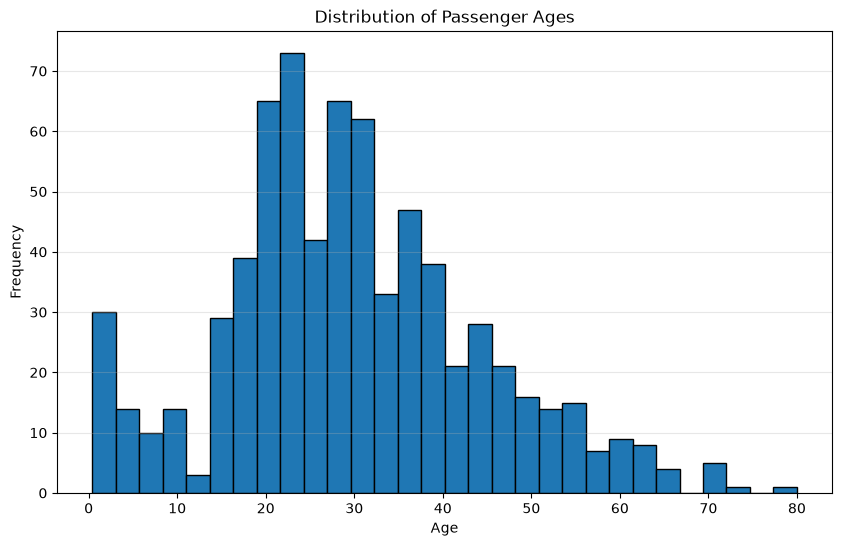

In [249]:
plt.figure(figsize=(10, 6))
plt.hist(data['Age'].dropna(), bins=30, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Passenger Ages')
plt.grid(axis='y', alpha=0.3)
plt.show()

2. Постройте гистограммы распределения цен для пассажиров разных классов

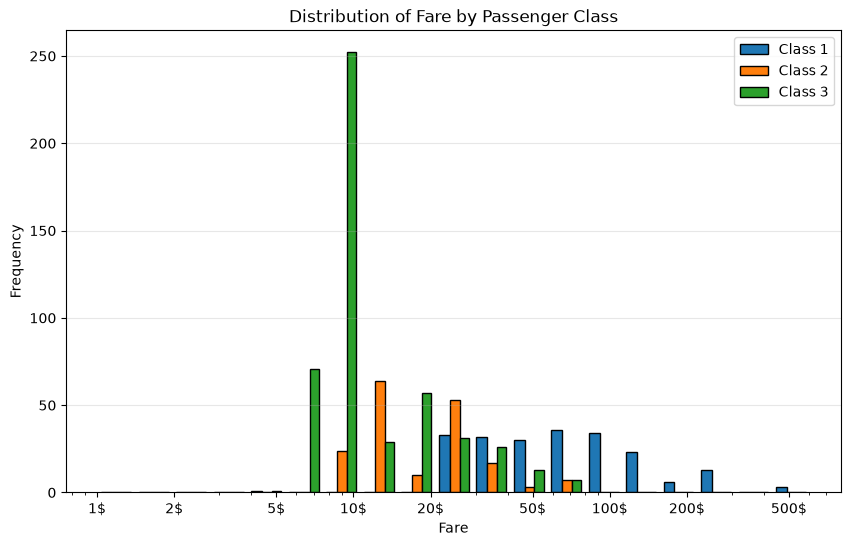

In [250]:
class1 = data[data['Pclass'] == 1]['Fare'].dropna()
class2 = data[data['Pclass'] == 2]['Fare'].dropna()
class3 = data[data['Pclass'] == 3]['Fare'].dropna()

plt.figure(figsize=(10, 6))

bins = np.logspace(0, np.log10(600), 20)

plt.hist([class1, class2, class3], bins=bins, edgecolor='black', label=['Class 1', 'Class 2', 'Class 3'])

plt.xscale('log')

plt.xticks([1, 2, 5, 10, 20, 50, 100, 200, 500], ['1$', '2$', '5$', '10$', '20$', '50$', '100$', '200$', '500$'])

plt.xlabel('Fare')
plt.ylabel('Frequency')
plt.title('Distribution of Fare by Passenger Class')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()


3. Постройте зависимость цены от возраста пассажира

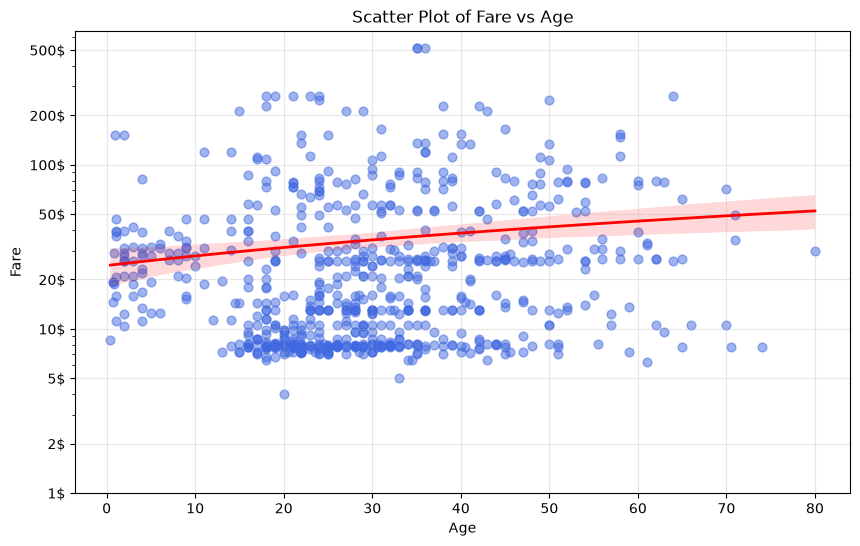

In [243]:
plt.figure(figsize=(10, 6))

sns.regplot(data=data, x='Age', y='Fare', color='royalblue', 
           scatter_kws={'alpha':0.5, 's':40}, line_kws={'color':'red', 'lw':2})

# or may be use
# plt.scatter(data['Age'], data['Fare'], alpha=0.5, color='teal', edgecolors='w', s=50, label='Passengers')

plt.yscale('log')
plt.yticks([1, 2, 5, 10, 20, 50, 100, 200, 500], ['1$', '2$', '5$', '10$', '20$', '50$', '100$', '200$', '500$'])

plt.xlabel('Age')
plt.ylabel('Fare')
plt.title('Scatter Plot of Fare vs Age')
plt.grid(True, alpha=0.3)
# plt.legend()
plt.show()

4. Постройте box plot отображающий распределение цен на билеты в разных классах

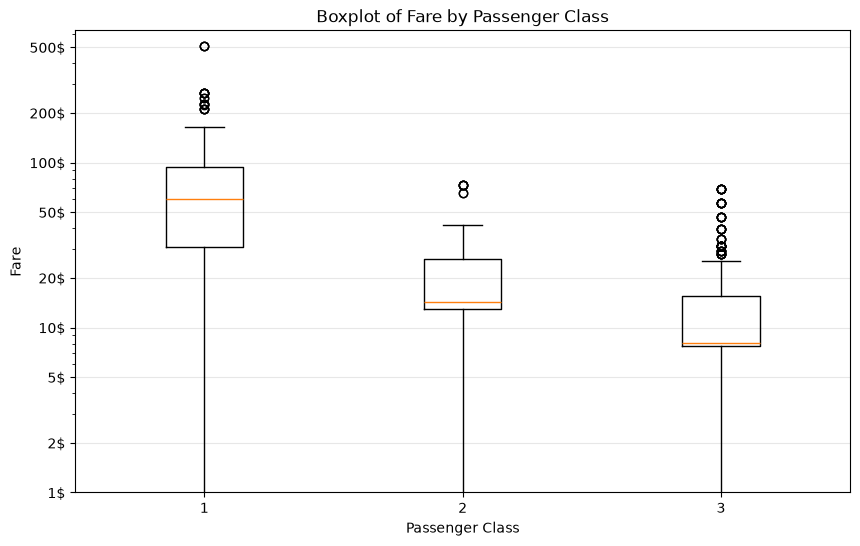

In [256]:
plt.figure(figsize=(10, 6))

plt.boxplot([class1, class2, class3], label=['Class 1', 'Class 2', 'Class 3'])

plt.yscale('log')
plt.yticks([1, 2, 5, 10, 20, 50, 100, 200, 500], ['1$', '2$', '5$', '10$', '20$', '50$', '100$', '200$', '500$'])

plt.xlabel('Passenger Class')
plt.ylabel('Fare')
plt.title('Boxplot of Fare by Passenger Class')
plt.grid(axis='y', alpha=0.3)
plt.show()

5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

Group
Children    0.590361
Men         0.163873
Women       0.756458
Name: Survived, dtype: float64


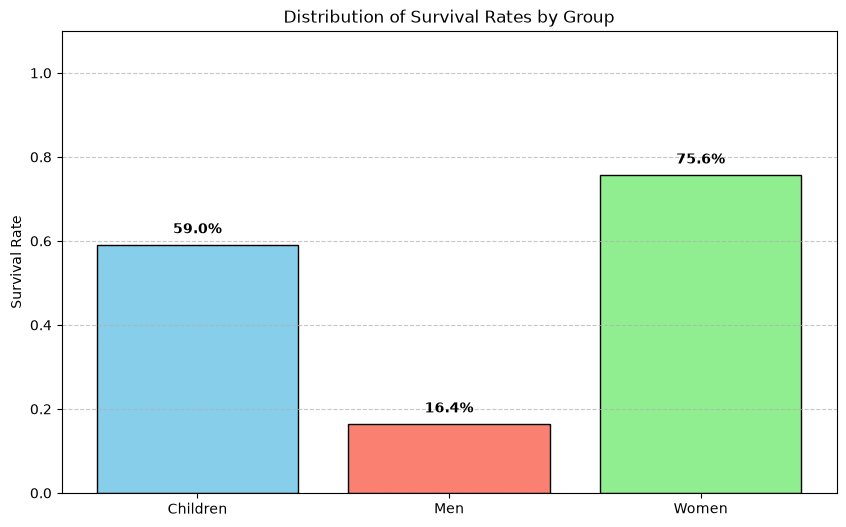

In [ ]:
def get_group(row):
    if row['Age'] < 16:
        return 'Children'
    elif row['Sex'] == 'male':
        return 'Men'
    else:
        return 'Women'

data['Group'] = data.apply(get_group, axis=1)

survival_rates = data.groupby('Group')['Survived'].mean()

plt.figure(figsize=(10, 6))
bars = plt.bar(survival_rates.index, survival_rates.values, color=['skyblue', 'salmon', 'lightgreen'], edgecolor='black')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f'{yval:.1%}', ha='center', va='bottom', fontweight='bold')

plt.ylabel('Survival Rate')
plt.title('Distribution of Survival Rates by Group')
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

In [168]:
data[data['Survived'] == 1]['Age'].mean()

np.float64(28.343689655172415)

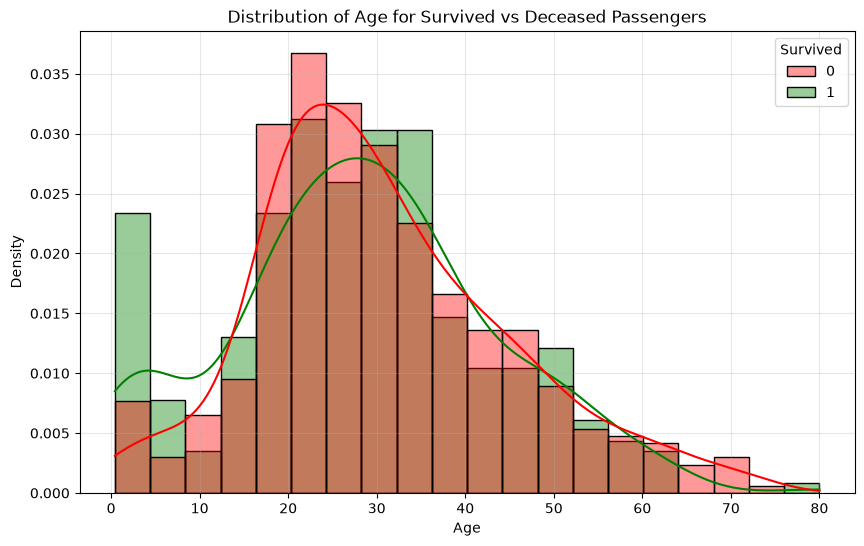

In [ ]:
plt.figure(figsize=(10, 6))

# Seaborn itself will separate by colors and build a legend if you use the hue parameter
sns.histplot(data=data.dropna(subset=['Age']), x='Age', hue='Survived', kde=True, stat='density', common_norm=False, alpha=0.4, palette={1: 'green', 0: 'red'})
plt.title('Distribution of Age for Survived vs Deceased Passengers')
plt.grid(True, alpha=0.3)
plt.show()

7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл

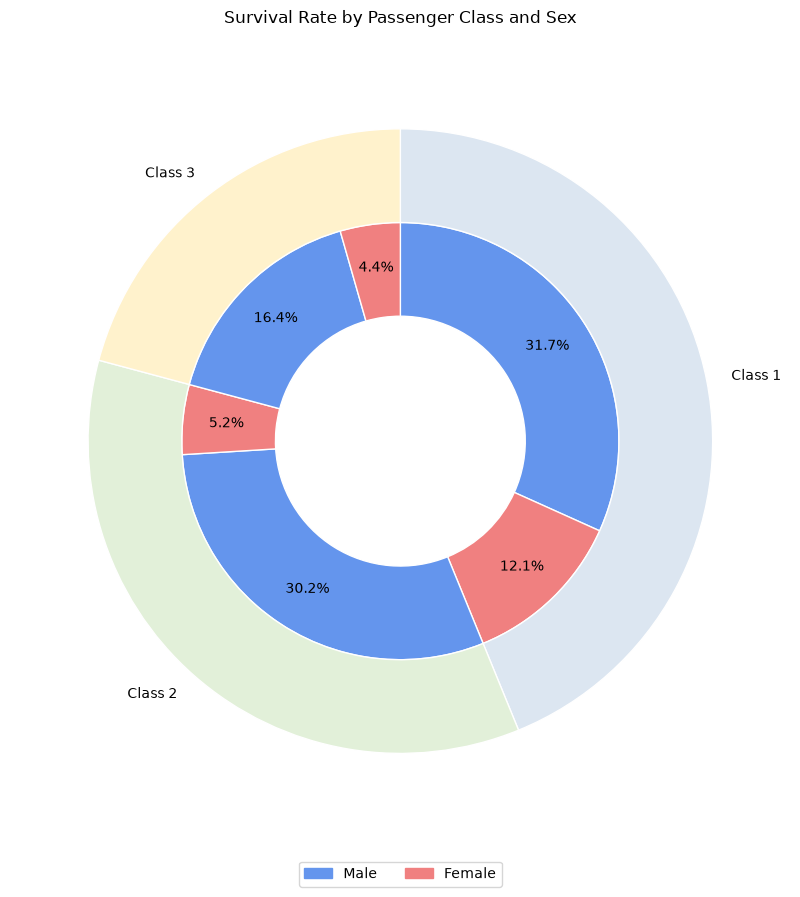

In [213]:
import matplotlib.pyplot as plt

MALE_COLOR = '#6495ED'
FEMALE_COLOR = '#F08080'

df = data.groupby(['Pclass', 'Sex'])['Survived'].mean().unstack()

CLASSES_QUANTITY = df.shape[0]

fig, ax = plt.subplots(figsize=(9, 9))

values = df.values.flatten()


colors = [MALE_COLOR, FEMALE_COLOR] * CLASSES_QUANTITY

# Inner circle - survival by gender
ax.pie(
    values,
    radius=0.7,
    colors=colors,
    startangle=90,
    counterclock=False,
    autopct='%1.1f%%',
    pctdistance=0.8,
    wedgeprops=dict(width=0.3, edgecolor='white')
)

# Outer circle - survival by class
ax.pie(
    [df.loc[cls].sum() for cls in df.index],
    radius=1,
    labels=[f'Class {cls}' for cls in df.index],
    startangle=90,
    counterclock=False,
    colors=['#DCE6F1', '#E2F0D9', '#FFF2CC'],
    wedgeprops=dict(width=0.3, edgecolor='white'),
    labeldistance=1.08
)

ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=MALE_COLOR, label='Male'),
        plt.Rectangle((0, 0), 1, 1, color=FEMALE_COLOR, label='Female')
    ],
    loc='lower center',
    bbox_to_anchor=(0.5, -0.08),
    ncol=2
)

ax.set_title('Survival Rate by Passenger Class and Sex', pad=20)

plt.tight_layout()
plt.show()